# Guided: the committee memo's claim and evidence, with the error bill computed

*The model justification: claim, evidence, caveat, action; the error bill in rupees under the chosen threshold. In pairs, before the unguided caveat, action and transfer.*

**Who needs the answer.** Meera's committee on Monday: one sentence of claim, two of evidence, each with a number you computed.

**The questions on the way.** What is the bill at two thresholds? How many buyers do 1,000 calls find? What do the claim and evidence say? What is the staleness rule in one sentence?

**How it runs.** Each TODO cell runs as shipped and prints `TO DO` until you replace the `None` or the empty string. The cell under it checks your number. The worked answer is the last section; open it only after your pair has a number in every TODO.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10.5, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED, LILAC = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#CFC9EE"

def check(label, ok):
    """Print PASS or FAIL on its own line; a failed check never stops the notebook."""
    print(("PASS  " if ok else "FAIL  ") + label)

# The Week 5 pipeline: the same file, columns and split every case notebook starts from.
import io, zipfile, pathlib, urllib.request
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0), cached after the first download."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        url = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
        outer = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
ECONOMY = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

bank = load_bank()
# Wednesday's honest set: no duration, and pdays split into a flag and the days for those contacted.
bank["never_contacted"] = (bank["pdays"] == 999).astype(int)
bank["days_since"] = bank["pdays"].where(bank["pdays"] != 999, 0)
COLS = PROFILE + HISTORY + ECONOMY + ["never_contacted", "days_since"]
X, y = bank[COLS], (bank["y"] == "yes").astype(int)

# The test slice is sealed first (the envelope on the wall); the rest splits 75/25.
rest, test = train_test_split(bank.index, test_size=0.20, stratify=y, random_state=42)
train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=42)
NUM = [c for c in COLS if pd.api.types.is_numeric_dtype(bank[c])]
CAT = [c for c in COLS if c not in NUM]

def logistic():
    prep = ColumnTransformer([("num", StandardScaler(), NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=3000))])

print(f"{len(bank):,} rows; train {len(train):,}, validation {len(val):,}, test {len(test):,} (sealed)")
print(f"buyers in validation: {y[val].sum():,} of {len(val):,} ({y[val].mean():.1%})")

CALL, MISS = 40, 1200          # Rs per wasted nudge, Rs of margin per missed buyer (Tuesday)
COST_T = CALL / (CALL + MISS)   # act when P(buy) is above 40 / 1,240 = 0.032

def bill_at(y_true, p, t):
    """The error bill at threshold t: wasted calls x Rs 40 plus missed buyers x Rs 1,200."""
    y_true, called = np.asarray(y_true), np.asarray(p) >= t
    tp = int((called & (y_true == 1)).sum()); fp = int((called & (y_true == 0)).sum())
    fn = int((~called & (y_true == 1)).sum())
    return {"called": tp + fp, "found": tp, "wasted": fp, "missed": fn, "bill_rs": CALL * fp + MISS * fn}

def bill_top(y_true, p, k):
    """The bill when the budget allows k calls: call the k highest scores."""
    y_true = np.asarray(y_true); top = np.argsort(-np.asarray(p), kind="stable")[:k]
    tp = int(y_true[top].sum()); fp, fn = k - tp, int(y_true.sum()) - tp
    return {"called": k, "found": tp, "wasted": fp, "missed": fn, "bill_rs": CALL * fp + MISS * fn,
            "score_at_cut": round(float(np.asarray(p)[top[-1]]), 3)}

model = logistic().fit(X.loc[train], y[train])
p, yv = model.predict_proba(X.loc[val])[:, 1], y[val].to_numpy()

def mark(label, mine, right, tol=0):
    if mine is None or mine == "":
        print("TO DO  " + label)
    else:
        check(label, abs(mine - right) <= tol)

41,188 rows; train 24,712, validation 8,238, test 8,238 (sealed)
buyers in validation: 928 of 8,238 (11.3%)


## Step 1: what is the bill at 0.032 and at 0.10?

Count the wasted calls (called, did not buy) and the missed buyers (not called, bought) at each threshold, then price them at Rs 40 and Rs 1,200. Use `p >= COST_T` (40 / 1,240, printed as 0.032) or `p >= 0.10` for "called" and `yv == 1` for "bought".

In [2]:
# TODO: replace each None with an expression
wasted_032 = None      # e.g. int(((p >= COST_T) & (yv == 0)).sum())
missed_032 = None
wasted_010 = None
missed_010 = None
bill_032 = None        # Rs 40 x wasted + Rs 1,200 x missed
bill_010 = None

In [3]:
truth_032, truth_010 = bill_at(yv, p, COST_T), bill_at(yv, p, 0.10)
mark("bill at 0.032", bill_032, truth_032["bill_rs"])
mark("bill at 0.10", bill_010, truth_010["bill_rs"])

TO DO  bill at 0.032
TO DO  bill at 0.10


## Step 2: how many buyers do the 1,000 calls Marketing can afford find?

Sort by score, take the top 1,000, count the buyers. At random the same 1,000 calls would find about 113.

In [4]:
# TODO: replace None
found_top_1000 = None  # hint: yv[np.argsort(-p)[:1000]].sum()

In [5]:
mark("buyers in the top 1,000", found_top_1000, bill_top(yv, p, 1000)["found"])

TO DO  buyers in the top 1,000


## Step 3: what do the claim and the evidence say?

One sentence of claim (this model, this operating point), two of evidence (the result against a baseline, in buyers or rupees). Every sentence carries a number from Steps 1 and 2.

In [6]:
# TODO: write the two parts
claim = ""
evidence = ""

In [7]:
for name, text in [("claim", claim), ("evidence", evidence)]:
    if not text:
        print("TO DO  " + name)
    else:
        check(f"the {name} carries a number", any(ch.isdigit() for ch in text))

TO DO  claim
TO DO  evidence


## Step 4: what is the staleness rule, in one sentence?

A rule names the number watched, the ceiling, the window and the owner. Write it so someone else could check it next month without asking you.

In [8]:
# TODO: one sentence
staleness_rule = ""
print(staleness_rule or "TO DO  staleness rule")

TO DO  staleness rule


## The worked answer

Open after your pair has a number in every TODO. The numbers come from this run.

0.032: wasted 6,502, missed 18, bill Rs 281,680
0.10:  wasted 1,324, missed 325, bill Rs 442,960
call everyone: Rs 292,400; top 1,000 finds 462 buyers

CLAIM.    Call the 1,000 customers the logistic model ranks highest (score above 0.245).
EVIDENCE. They hold 462 buyers against about 113 at random. Without a budget, at 0.032, the bill is Rs 281,680, within 4% of calling everyone.
RULE.     If the share of called customers who subscribe sits more than 10 points from the share the model promised for two months running, Kavya pauses the list and the model goes back for a refit.


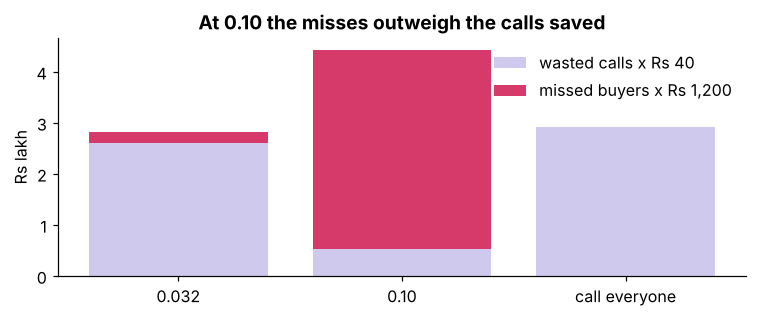

PASS  the bill at 0.10 is larger than at 0.032
PASS  the top 1,000 finds more than four times the random count


In [9]:
a, b, top = bill_at(yv, p, COST_T), bill_at(yv, p, 0.10), bill_top(yv, p, 1000)
everyone = bill_at(yv, np.ones(len(yv)), 0.5)
print(f"0.032: wasted {a['wasted']:,}, missed {a['missed']}, bill Rs {a['bill_rs']:,}")
print(f"0.10:  wasted {b['wasted']:,}, missed {b['missed']}, bill Rs {b['bill_rs']:,}")
print(f"call everyone: Rs {everyone['bill_rs']:,}; top 1,000 finds {top['found']} buyers")
print()
print(f"CLAIM.    Call the 1,000 customers the logistic model ranks highest (score above {top['score_at_cut']:.3f}).")
print(f"EVIDENCE. They hold {top['found']} buyers against about 113 at random. Without a budget, at 0.032, "
      f"the bill is Rs {a['bill_rs']:,}, within {1 - a['bill_rs'] / everyone['bill_rs']:.0%} of calling everyone.")
print("RULE.     If the share of called customers who subscribe sits more than 10 points from the share the model "
      "promised for two months running, Kavya pauses the list and the model goes back for a refit.")

fig, ax = plt.subplots(figsize=(7, 3))
labels = ["0.032", "0.10", "call everyone"]
wasted = [a["wasted"] * 40 / 1e5, b["wasted"] * 40 / 1e5, everyone["wasted"] * 40 / 1e5]
missed = [a["missed"] * 1200 / 1e5, b["missed"] * 1200 / 1e5, 0]
ax.bar(labels, wasted, color=LILAC, label="wasted calls x Rs 40")
ax.bar(labels, missed, bottom=wasted, color=ROSE, label="missed buyers x Rs 1,200")
ax.set_ylabel("Rs lakh"); ax.legend(frameon=False); ax.set_title("At 0.10 the misses outweigh the calls saved")
plt.tight_layout(); plt.show()
check("the bill at 0.10 is larger than at 0.032", b["bill_rs"] > a["bill_rs"])
check("the top 1,000 finds more than four times the random count", top["found"] > 4 * 113)